In [1]:

from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_PATH = "/content/drive/MyDrive/Colab Notebooks/IDSE_PROJECT"

DATA_PATH = os.path.join(PROJECT_PATH, "processed_data")
MODEL_PATH = os.path.join(PROJECT_PATH, "models")
RESULT_PATH = os.path.join(PROJECT_PATH, "results")

os.makedirs(DATA_PATH, exist_ok=True)
os.makedirs(MODEL_PATH, exist_ok=True)
os.makedirs(RESULT_PATH, exist_ok=True)

print("Project folder connected successfully")


Mounted at /content/drive
Project folder connected successfully


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

baseline_results = pd.read_csv(
    os.path.join(RESULT_PATH, "baseline_results.csv")
)

logistic_results = pd.read_csv(
    os.path.join(RESULT_PATH, "logistic_regression_results.csv")
)

random_forest_results = pd.read_csv(
    os.path.join(RESULT_PATH, "random_forest_results.csv")
)

print("All model results loaded")


All model results loaded


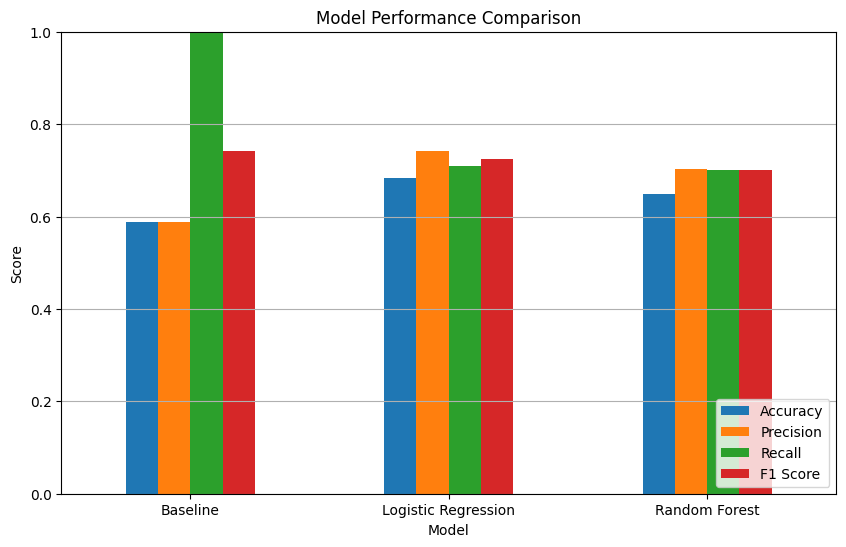

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

# Combine the individual model results that are already loaded in memory
results = pd.concat([
    baseline_results,
    logistic_results,
    random_forest_results
], ignore_index=True)

# Rename F1_Score to F1 Score to match the plotting requirements
results = results.rename(columns={"F1_Score": "F1 Score"})

# Fill missing columns (like Precision, Recall, F1 Score for Baseline if not present) with 0
for col in ["Accuracy", "Precision", "Recall", "F1 Score"]:
    if col not in results.columns:
        results[col] = 0.0

# Plot the model performance comparison
results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.legend(loc="lower right")
plt.savefig(
    os.path.join(RESULT_PATH, "model_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [10]:
import numpy as np
import pandas as pd
import os
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define baseline_pred by predicting the majority class (1) for all samples
baseline_pred = np.ones(len(y_test))

baseline_results = pd.DataFrame({
    "Model": ["Baseline"],
    "Accuracy": [accuracy_score(y_test, baseline_pred)],
    "Precision": [precision_score(y_test, baseline_pred, zero_division=0)],
    "Recall": [recall_score(y_test, baseline_pred, zero_division=0)],
    "F1_Score": [f1_score(y_test, baseline_pred, zero_division=0)]
})

baseline_results.to_csv(
    os.path.join(RESULT_PATH, "baseline_results.csv"),
    index=False
)

print(baseline_results)

      Model  Accuracy  Precision  Recall  F1_Score
0  Baseline  0.588855   0.588855     1.0  0.741232


            Feature  Importance
2      TotalRevenue    0.237486
1     TotalQuantity    0.218251
5       RecencyDays    0.214111
3  ProductDiversity    0.184652
0  InvoiceFrequency    0.074052
4        ActiveDays    0.071448


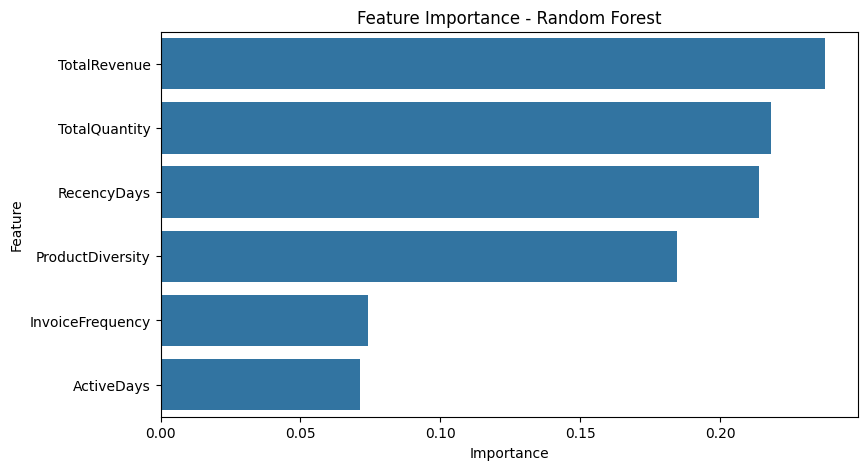

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

# Ensure random_forest_model is loaded
if 'random_forest_model' not in globals():
    random_forest_model = joblib.load(os.path.join(MODEL_PATH, "random_forest.pkl"))

# Construct the feature importance DataFrame using X_test columns and the loaded model
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.savefig(
    os.path.join(RESULT_PATH, "feature_importance.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [23]:
customer_predictions = X_test.copy()

customer_predictions["Actual"] = y_test

# Updated to use the correct loaded variable name 'random_forest_model'
customer_predictions["Predicted"] = random_forest_model.predict(
    X_test
)

customer_predictions["Prediction"] = (
    customer_predictions["Predicted"].map({
        0: "Not Returned",
        1: "Repeat Purchase"
    })
)

print(customer_predictions.head(10))

   InvoiceFrequency  TotalQuantity  TotalRevenue  ProductDiversity  \
0                 1            122        498.48                13   
1                 2            206        414.26                 7   
2                 1            173        116.28                 9   
3                 2            208        389.44                22   
4                 2            454        464.68                 3   
5                 2            474        712.29                34   
6                 1             48         95.76                 5   
7                 2            267        645.65                13   
8                 3            226        542.20                20   
9                 1            111        292.63                16   

   ActiveDays  RecencyDays  Actual  Predicted       Prediction  
0           1           30       0          1  Repeat Purchase  
1           2           77       1          1  Repeat Purchase  
2           1           70       1

In [24]:
import os
import pandas as pd

print("CUSTOMER PURCHASE BEHAVIOUR ANALYSIS")
print("------------------------------------")

# Attempt to load the original customer data if it exists
customer_data_path = os.path.join(DATA_PATH, "customer_data.csv")
if os.path.exists(customer_data_path):
    customer_data = pd.read_csv(customer_data_path)
    total_customers = customer_data.shape[0]
    returned_sum = customer_data["Returned"].sum()
    not_returned_sum = (customer_data["Returned"] == 0).sum()
    dataset_label = "(Full Dataset)"
else:
    # Fallback to test set if full dataset is not present
    total_customers = len(X_test)
    returned_sum = y_test.sum()
    not_returned_sum = (y_test == 0).sum()
    dataset_label = "(Test Set)"

print(f"Total customers {dataset_label}: {total_customers}")
print(f"Customers who made repeat purchases {dataset_label}: {returned_sum}")
print(f"Customers who did not make repeat purchases {dataset_label}: {not_returned_sum}")

print("\nModel Comparison:")
print(results)

print("\nMost Important Features:")
print(feature_importance.head())

CUSTOMER PURCHASE BEHAVIOUR ANALYSIS
------------------------------------
Total customers (Test Set): 664
Customers who made repeat purchases (Test Set): 391
Customers who did not make repeat purchases (Test Set): 273

Model Comparison:
                 Model  Accuracy  Precision    Recall  F1 Score
0             Baseline  0.588855   0.588855  1.000000  0.741232
1  Logistic Regression  0.683735   0.742627  0.708440  0.725131
2        Random Forest  0.649096   0.702564  0.700767  0.701665

Most Important Features:
            Feature  Importance
2      TotalRevenue    0.237486
1     TotalQuantity    0.218251
5       RecencyDays    0.214111
3  ProductDiversity    0.184652
0  InvoiceFrequency    0.074052


In [25]:
logistic_model = joblib.load(
    os.path.join(MODEL_PATH, "logistic_regression.pkl")
)

random_forest_model = joblib.load(
    os.path.join(MODEL_PATH, "random_forest.pkl")
)